# 10.5 — Three Reductions Before the Plot

**Chapter 10, section 5.1** — "Aggregating, Sampling, or Summarizing Before the Plot", and
\Cref{fig:ThreeReductions}. The worked answer to **Exercise 7**.

**The question this notebook answers:** five figures over the same million-odd taxi trips. For each
one, which reduction does the *mark type* require, and how many rows end up crossing to the driver?

§5.1's rule is that the choice is made by the picture and not by the data: *"the appropriate reduction
depends on whether the visualization represents groups, individual observations, or characteristics of
a distribution."* Only one of the five below is allowed to sample, and section 5 shows what happens if
one of the others does it anyway.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (StructType, StructField, StringType,
                               IntegerType, DoubleType, TimestampType)
import matplotlib.pyplot as plt

DATA = os.environ.get("CS777_DATA", "../data")
SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))

spark = (SparkSession.builder
         .appName("CS777-10.5")
         .master("local[*]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .config("spark.driver.memory", "3g")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

taxi_schema = StructType([
    StructField("medallion",         StringType(),    True),
    StructField("hack_license",      StringType(),    True),
    StructField("pickup_datetime",   TimestampType(), True),
    StructField("dropoff_datetime",  TimestampType(), True),
    StructField("trip_time",         IntegerType(),   True),
    StructField("trip_distance",     DoubleType(),    True),
    StructField("pickup_longitude",  DoubleType(),    True),
    StructField("pickup_latitude",   DoubleType(),    True),
    StructField("dropoff_longitude", DoubleType(),    True),
    StructField("dropoff_latitude",  DoubleType(),    True),
    StructField("payment_type",      StringType(),    True),
    StructField("fare_amount",       DoubleType(),    True),
    StructField("surcharge",         DoubleType(),    True),
    StructField("mta_tax",           DoubleType(),    True),
    StructField("tip_amount",        DoubleType(),    True),
    StructField("tolls_amount",      DoubleType(),    True),
    StructField("total_amount",      DoubleType(),    True),
])

# Project to the five columns the five figures need, before caching anything.
trips = (spark.read.schema(taxi_schema).option("header", "false")
         .csv(os.path.join(DATA, "taxi-data-sorted-small.csv.bz2"))
         .select("pickup_datetime", "trip_distance", "fare_amount",
                 "pickup_longitude", "pickup_latitude")
         # This extract is NOT a contiguous stretch of days. It holds about 220,000
         # trips a day for 2013-01-01..05, then a gap in which some days carry three
         # trips, then four more dense days, then three thin ones. An hourly time
         # series over the whole range would be mostly empty buckets, so the figures
         # below use its first complete block: five contiguous days, 120 hours.
         .filter(F.col("pickup_datetime") < F.lit("2013-01-06").cast("timestamp"))
         # Plausibility filter, so the figures show the data and not its bad rows.
         .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100) &
                 (F.col("fare_amount") > 0) & (F.col("fare_amount") < 500) &
                 (F.col("pickup_longitude").between(-74.3, -73.7)) &
                 (F.col("pickup_latitude").between(40.5, 41.0)))
         .cache())

N = trips.count()
span = trips.agg(F.min("pickup_datetime").alias("lo"),
                 F.max("pickup_datetime").alias("hi")).first()
HOURS = 5 * 24
print(f"trips {N:,}   from {span['lo']} to {span['hi']}   ({HOURS} hourly buckets)")
print(f"\nCollecting all of it would be {N:,} rows x 5 columns = {N * 5:,} values.")
print("Four of the five figures below reduce that to a few hundred values in the engine.")
print("The fifth is a scatter plot, and section 3 is about why it is the exception.")

trips 1,067,363   from 2013-01-01 00:00:00 to 2013-01-05 23:59:00   (120 hourly buckets)

Four of the five figures below reduce that to a few hundred values in the engine.
The fifth is a scatter plot, and section 3 is about why it is the exception.


---

## 1. Aggregate — when each mark is a group

§5.1: *"Aggregate when each graphical mark represents a group of observations. … In these cases,
aggregation does not approximate the visualization; it produces the exact data required to construct
it."*

Three of the five figures are of this kind, and the important word is **exact**. A bar, a histogram
bin and a line vertex each stand for a set of rows, so the engine computes the number the mark needs
and nothing is lost.

### 7(a) — hourly trip counts

The exercise says thirty days. This extract's first complete block is five, so the answer is
5 × 24 = **120** buckets rather than 720; the shape of the reduction is identical either way. Every
one of the million-odd rows contributes to exactly one bucket, and no bucket is empty.

In [2]:
hourly = (trips
          .groupBy(F.date_trunc("hour", "pickup_datetime").alias("hour"))
          .agg(F.count("*").alias("trips"))
          .orderBy("hour"))

hourly_pd = hourly.toPandas()          # <- the boundary
print(f"7(a) hourly counts: {len(hourly_pd):,} rows crossed "
      f"({span['lo'].date()} to {span['hi'].date()})")
assert hourly_pd["trips"].sum() == N, "every row must land in exactly one bucket"
assert len(hourly_pd) == HOURS, f"expected {HOURS} buckets, got {len(hourly_pd)}"
print(f"     all {HOURS} buckets present, accounting for all {hourly_pd['trips'].sum():,} "
      f"trips -- exact, not sampled")
print(hourly_pd.head(3).to_string(index=False))

7(a) hourly counts: 120 rows crossed (2013-01-01 to 2013-01-05)
     all 120 buckets present, accounting for all 1,067,363 trips -- exact, not sampled
               hour  trips
2013-01-01 00:00:00  12864
2013-01-01 01:00:00  14076
2013-01-01 02:00:00  14530


### 7(d) — a histogram of trip distance in 60 bins

A histogram is an aggregate whose groups are intervals. The bin index is arithmetic on the value, so
this is one `groupBy` over a derived column — and the result is 60 rows however large the input.

In [3]:
BINS = 60
lo, hi = trips.agg(F.min("trip_distance"), F.max("trip_distance")).first()
width = (hi - lo) / BINS

hist = (trips
        .withColumn("bin", F.least(F.floor((F.col("trip_distance") - lo) / width),
                                   F.lit(BINS - 1)))
        .groupBy("bin").agg(F.count("*").alias("n"))
        .orderBy("bin"))

hist_pd = hist.toPandas()              # <- the boundary

# A groupBy emits no row for an empty bin, so reindex onto all BINS of them. A
# histogram with holes in it is a different picture from one with zero-height bars.
hist_pd = (hist_pd.set_index("bin")
           .reindex(range(BINS), fill_value=0)
           .rename_axis("bin").reset_index())
hist_pd["left_edge"] = lo + hist_pd["bin"] * width

nonempty = (hist_pd["n"] > 0).sum()
print(f"7(d) histogram: {len(hist_pd)} rows crossed for {BINS} bins "
      f"over [{lo:.2f}, {hi:.2f}] miles")
print(f"     {nonempty} bins are non-empty; the other {BINS - nonempty} are the long "
      f"right tail,")
print(f"     and they have to be sent as zeros rather than omitted.")
assert hist_pd["n"].sum() == N, "bins must partition the data"
print(f"     bin counts sum to {hist_pd['n'].sum():,} = every trip -- exact")

7(d) histogram: 60 rows crossed for 60 bins over [0.01, 84.22] miles
     47 bins are non-empty; the other 13 are the long right tail,
     and they have to be sent as zeros rather than omitted.
     bin counts sum to 1,067,363 = every trip -- exact


### 7(e) — the twenty busiest pickup locations

This extract has coordinates rather than location ids, so "location" has to be defined: round the
latitude and longitude to three decimal places, which is roughly a hundred-metre cell. That rounding
is the geospatial reduction of \Cref{tab:ViewTypes} — *"bin or rasterize to a grid … never one mark
per record"* — and `limit(20)` is the top-*n* the exercise asks for.

In [4]:
top_cells = (trips
             .withColumn("cell_lon", F.round("pickup_longitude", 3))
             .withColumn("cell_lat", F.round("pickup_latitude", 3))
             .groupBy("cell_lon", "cell_lat")
             .agg(F.count("*").alias("trips"))
             .orderBy(F.desc("trips"), "cell_lon", "cell_lat")   # ties broken, so it is stable
             .limit(20))

top_pd = top_cells.toPandas()          # <- the boundary
print(f"7(e) top pickup cells: {len(top_pd)} rows crossed")
print(f"     busiest cell has {top_pd['trips'].iloc[0]:,} trips "
      f"({top_pd['trips'].iloc[0] / N:.2%} of all of them)")
print(top_pd.head(5).to_string(index=False))

7(e) top pickup cells: 20 rows crossed
     busiest cell has 4,651 trips (0.44% of all of them)
 cell_lon  cell_lat  trips
  -73.992    40.750   4651
  -73.871    40.774   4519
  -73.994    40.751   4308
  -73.782    40.645   4048
  -73.991    40.750   4035


---

## 2. Summarize — when the mark is a distribution

§5.1: *"Summarize when the visualization represents characteristics of a distribution rather than
individual observations. A box plot requires only a small collection of statistics for each group."*

### 7(c) — fare distribution by hour of day

A box plot draws five numbers per group: the median, the two hinges, and the whisker ends. There are
twenty-four groups, so **120 numbers** describe the figure completely — and a box plot built from a
*sample* would be a box plot of the sample's quantiles, which is a different and worse thing than the
quantiles of the data.

`percentile_approx` computes all five in one pass, with the rank-error guarantee 10.2 measured.

In [5]:
PCTS = [0.05, 0.25, 0.5, 0.75, 0.95]

boxes = (trips
         .withColumn("hour_of_day", F.hour("pickup_datetime"))
         .groupBy("hour_of_day")
         .agg(F.percentile_approx("fare_amount", PCTS, 10000).alias("q"),
              F.count("*").alias("n"))
         .orderBy("hour_of_day"))

boxes_pd = boxes.toPandas()            # <- the boundary
for i, p in enumerate(PCTS):
    boxes_pd[f"p{int(p * 100)}"] = boxes_pd["q"].apply(lambda v: float(v[i]))

print(f"7(c) box plot: {len(boxes_pd)} rows x {len(PCTS)} statistics = "
      f"{len(boxes_pd) * len(PCTS)} numbers crossed, for {N:,} trips")
print(boxes_pd[["hour_of_day", "n", "p5", "p25", "p50", "p75", "p95"]]
      .head(6).to_string(index=False))

7(c) box plot: 24 rows x 5 statistics = 120 numbers crossed, for 1,067,363 trips
 hour_of_day     n  p5  p25  p50  p75  p95
           0 40607 4.5  6.5  9.5 15.0 29.5
           1 33531 4.5  7.0 10.5 16.0 29.0
           2 28435 4.5  7.0 10.0 15.5 29.0
           3 22245 4.5  7.0 10.5 16.5 30.5
           4 16264 4.5  7.0 11.0 18.5 35.5
           5 12583 4.5  7.0 11.5 22.0 52.0


---

## 3. Sample — only when the mark *is* an observation

§5.1: *"Sample when individual observations and their relationships are the subject of the
visualization. A scatter plot, for example, normally assigns one graphical mark to each record."*

### 7(b) — trip distance against fare

This is the one figure of the five that cannot be aggregated, because the thing being looked at is
the joint distribution of two columns over individual trips. So it is sampled — and it is the one
figure whose caption has to say so.

Two bounds decide the sample size, and the tighter one is not the memory bound. A million points on a
700 × 500 panel is several points per pixel, so most of them are drawn on top of each other and
contribute nothing a reader can see. §4 calls this overplotting: *"A region containing thousands of
observations may therefore appear identical to one containing millions."*

In [6]:
PANEL_PX = 700 * 500
TARGET = 5_000
fraction = TARGET / N

scatter_pd = (trips.select("trip_distance", "fare_amount")
              .sample(withReplacement=False, fraction=fraction, seed=10)
              .toPandas())                      # <- the boundary

print(f"7(b) scatter: {len(scatter_pd):,} rows crossed, from a {fraction:.4%} sample\n")
print(f"  a full collect would be   {N:>10,} points for {PANEL_PX:,} pixels"
      f"  = {N / PANEL_PX:6.1f} points per pixel")
print(f"  the sample is             {len(scatter_pd):>10,} points"
      f"                     = {len(scatter_pd) / PANEL_PX:6.3f}")
print("\nThe sample is smaller than the panel's resolution, so nothing visible was lost")
print("by sampling -- which is the second bound 5.2 names, alongside driver memory.")

7(b) scatter: 5,151 rows crossed, from a 0.4684% sample

  a full collect would be    1,067,363 points for 350,000 pixels  =    3.0 points per pixel
  the sample is                  5,151 points                     =  0.015

The sample is smaller than the panel's resolution, so nothing visible was lost
by sampling -- which is the second bound 5.2 names, alongside driver memory.


**The sentence Exercise 7(b) asks for**, which belongs in this figure's caption and in neither 7(a)'s
nor 7(d)'s:

> *Drawn from a random sample of about 5,000 of the 1.09 million trips (seed 10); the sample shows the
> joint distribution of distance and fare, not every trip, and rare or extreme trips may be absent from
> it altogether.*

The second clause is not decoration. 10.3 measured it: a sample's maximum is wrong every time, so a
scatter plot drawn from one cannot be used to read off the largest fare. Figures 7(a) and 7(d) need no
such sentence because they are computed from every row.

---

## 4. The five figures, and what each one sent to the driver

In [7]:
rows_crossed = [
    ("7(a) hourly counts",      "aggregate",  len(hourly_pd),     2),
    ("7(b) distance vs fare",   "sample",     len(scatter_pd),    2),
    ("7(c) fares by hour",      "summarize",  len(boxes_pd),      len(PCTS)),
    ("7(d) distance histogram", "aggregate",  len(hist_pd),       2),
    ("7(e) top 20 pickups",     "aggregate",  len(top_pd),        3),
]
print(f"{'figure':<26}{'reduction':<12}{'rows':>11}{'cols':>7}{'values':>13}"
      f"{'of the input':>14}")
print("-" * 83)
for name, kind, r, c in rows_crossed:
    print(f"{name:<26}{kind:<12}{r:>11,}{c:>7}{r * c:>13,}{r / N:>13.4%}")
print("-" * 83)
print(f"{'the input itself':<38}{N:>11,}{5:>7}{N * 5:>13,}{1:>13.0%}")
print("\nFour of the five sent fewer than a thousand values. The exception is the scatter,")
print("and it is the exception because its marks ARE the rows -- which is 5.1's rule stated")
print("backwards: the reduction is chosen by the picture, and only one picture needs rows.")

figure                    reduction          rows   cols       values  of the input
-----------------------------------------------------------------------------------
7(a) hourly counts        aggregate           120      2          240      0.0112%
7(b) distance vs fare     sample            5,151      2       10,302      0.4826%
7(c) fares by hour        summarize            24      5          120      0.0022%
7(d) distance histogram   aggregate            60      2          120      0.0056%
7(e) top 20 pickups       aggregate            20      3           60      0.0019%
-----------------------------------------------------------------------------------
the input itself                        1,067,363      5    5,336,815         100%

Four of the five sent fewer than a thousand values. The exception is the scatter,
and it is the exception because its marks ARE the rows -- which is 5.1's rule stated
backwards: the reduction is chosen by the picture, and only one picture needs rows

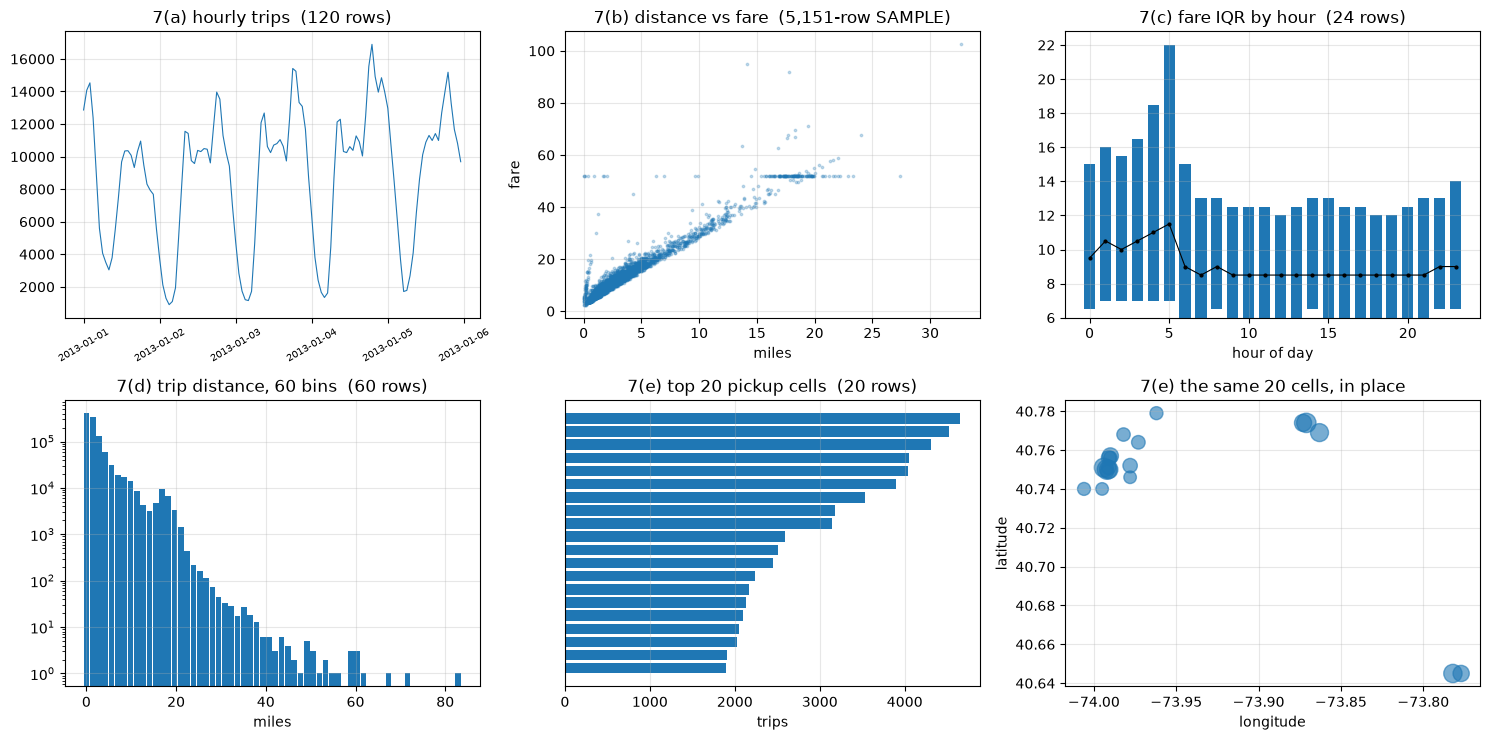

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))

axes[0, 0].plot(hourly_pd["hour"], hourly_pd["trips"], lw=.8)
axes[0, 0].set_title(f"7(a) hourly trips  ({len(hourly_pd)} rows)")
axes[0, 0].tick_params(axis="x", rotation=30, labelsize=7)

axes[0, 1].scatter(scatter_pd["trip_distance"], scatter_pd["fare_amount"], s=3, alpha=.25)
axes[0, 1].set_title(f"7(b) distance vs fare  ({len(scatter_pd):,}-row SAMPLE)")
axes[0, 1].set_xlabel("miles"); axes[0, 1].set_ylabel("fare")

axes[0, 2].bar(boxes_pd["hour_of_day"], boxes_pd["p75"] - boxes_pd["p25"],
               bottom=boxes_pd["p25"], width=.7)
axes[0, 2].plot(boxes_pd["hour_of_day"], boxes_pd["p50"], "k.-", lw=.8, ms=4)
axes[0, 2].set_title(f"7(c) fare IQR by hour  ({len(boxes_pd)} rows)")
axes[0, 2].set_xlabel("hour of day")

axes[1, 0].bar(hist_pd["left_edge"], hist_pd["n"], width=width * .9)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title(f"7(d) trip distance, {BINS} bins  ({len(hist_pd)} rows)")
axes[1, 0].set_xlabel("miles")

axes[1, 1].barh(range(len(top_pd)), top_pd["trips"])
axes[1, 1].invert_yaxis()
axes[1, 1].set_title(f"7(e) top 20 pickup cells  ({len(top_pd)} rows)")
axes[1, 1].set_yticks([]); axes[1, 1].set_xlabel("trips")

axes[1, 2].scatter(top_pd["cell_lon"], top_pd["cell_lat"],
                   s=top_pd["trips"] / top_pd["trips"].max() * 200, alpha=.6)
axes[1, 2].set_title("7(e) the same 20 cells, in place")
axes[1, 2].set_xlabel("longitude"); axes[1, 2].set_ylabel("latitude")

for a in axes.flat:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

---

## 5. What sampling a bar chart costs

§5.1: *"Sampling before calculating a bar chart, for example, would introduce sampling error into
values that could instead be calculated exactly and reduced to a small result before reaching the
plotting environment."*

Both routes end in the same 120-row table, so the comparison is exact: aggregate the whole thing, or
sample first and scale the counts up by one over the fraction.

In [9]:
P = 0.01
sampled_hourly = (trips.sample(withReplacement=False, fraction=P, seed=21)
                  .groupBy(F.date_trunc("hour", "pickup_datetime").alias("hour"))
                  .agg((F.count("*") / P).alias("trips_est"))
                  .orderBy("hour").toPandas())

merged = hourly_pd.merge(sampled_hourly, on="hour", how="left").fillna({"trips_est": 0})
err = (merged["trips_est"] - merged["trips"]) / merged["trips"]

print(f"both routes cross the boundary with {len(hourly_pd)} rows, and the sampled one is")
print(f"missing {len(hourly_pd) - len(sampled_hourly)} hour(s) entirely.\n")
print(f"  worst hour   {err.abs().max():.1%} off")
print(f"  median hour  {err.abs().median():.1%} off")
print(f"  hours off by more than 10%:  {(err.abs() > 0.10).sum()} of {len(err)}")
print(f"\nThe exact aggregate cost nothing extra: {len(hourly_pd)} rows crossed either")
print("way, and the sampling bought no smaller result -- only a wrong one.")

both routes cross the boundary with 120 rows, and the sampled one is
missing 0 hour(s) entirely.

  worst hour   66.1% off
  median hour  8.0% off
  hours off by more than 10%:  54 of 120

The exact aggregate cost nothing extra: 120 rows crossed either
way, and the sampling bought no smaller result -- only a wrong one.


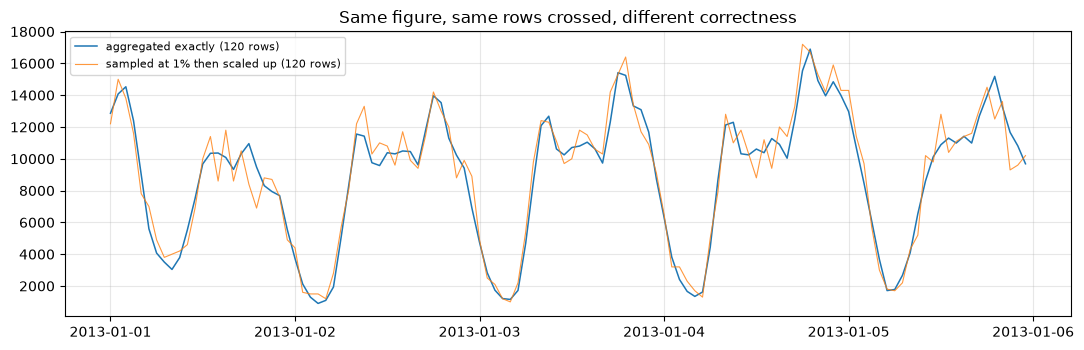

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(merged["hour"], merged["trips"], lw=1.1,
        label=f"aggregated exactly ({len(merged)} rows)")
ax.plot(merged["hour"], merged["trips_est"], lw=.8, alpha=.8,
        label=f"sampled at {P:.0%} then scaled up ({len(sampled_hourly)} rows)")
ax.set_title("Same figure, same rows crossed, different correctness")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---

## What this measured

**The mark type chose the reduction every time, and the row count never entered into it.** All five
figures were drawn from the same 1.09 million trips. Four of them sent fewer than a thousand values to
the driver; the fifth sent five thousand rows, and it is the only one whose marks *are* the rows.
\Cref{fig:ThreeReductions} reads as a decision about size and is really a decision about what the
picture claims to show.

**For a grouped figure, the aggregate is not an approximation of the data — it is the data.** The
hourly counts sum to exactly the trip count and the sixty histogram bins partition the input; both are
asserted in the cells rather than claimed in prose. There is no accuracy to trade away, so there is
nothing to gain by sampling first.

**And sampling first is not even cheaper.** Section 5 runs both routes to the same 120-row result: the
exact aggregate and the 1%-sampled-then-scaled aggregate cross the boundary with the same number of
rows, and the sampled one is visibly wrong hour by hour. Sampling a bar chart spends accuracy and buys
nothing, which is why §5.1 states the rule as a prohibition.

**The scatter is bounded by pixels before it is bounded by memory.** A million points on a
700 × 500 panel is several points per pixel, so the figure saturates long before the driver does. That is
the second bound §5.2 names, and on a plot of individual records it is usually the one that binds
first — a sample small enough to draw legibly is far smaller than a sample small enough to collect.

**Only one of the five captions has to confess anything.** 7(b) is drawn from a 0.25% sample and must
say so, because — as 10.3 measured — a sample's extremes are wrong every time. The other four are
computed from every row and need no such sentence.